# Semana 8 · Implementación y comparación de algoritmos de clasificación
**CADI Introducción a Machine Learning — Universidad de Cundinamarca**
**Estudiante:** Jonnathan Pazos · **Modalidad:** trabajo individual asincrónico

**Pregunta orientadora:** ¿Cómo seleccionar el algoritmo de clasificación más adecuado según las características del problema, los datos y los resultados de evaluación?

Se comparan cinco clasificadores (Decision Tree, Random Forest, SVM, K-NN y Naive Bayes) sobre el dataset *Breast Cancer Wisconsin Diagnostic*, manteniendo **la misma partición entrenamiento/prueba y las mismas métricas** para todos. Se incluye además la Regresión Logística como línea base opcional.

>  El dataset se usa solo con fines académicos. Los resultados no constituyen una herramienta clínica.

## 0. Librerías

In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset, partición y métricas
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

# Preprocesamiento y modelos
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression

## 1. Ejercicio 1 — Preparación del caso y los datos
### 1.1 Carga del dataset y definición de la variable objetivo
En el dataset original `target = 0` es **maligno** y `target = 1` es **benigno**. Como el interés es detectar casos malignos, se invierte la etiqueta para que la **clase positiva (1) = maligno**.

In [2]:
# Cargar el dataset en formato DataFrame
data = load_breast_cancer(as_frame=True)

# Variables de entrada (X): 30 mediciones numéricas de los núcleos celulares
X = data.data.copy()

# Variable objetivo (y): 1 = maligno, 0 = benigno (se invierte la codificación original)
y = (data.target == 0).astype(int)

print('Dimensiones de X:', X.shape)
print('\nConteo de clases:')
print(y.value_counts())
print('\nProporción de clases:')
print(y.value_counts(normalize=True).round(3))

Dimensiones de X: (569, 30)

Conteo de clases:
target
0    357
1    212
Name: count, dtype: int64

Proporción de clases:
target
0    0.627
1    0.373
Name: proportion, dtype: float64


In [3]:
# Vista general de las variables de entrada
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
# Estadísticos descriptivos: se observa que las variables tienen escalas muy diferentes
desc = X.describe().T[['mean', 'std', 'min', 'max']]
print(desc.sort_values('max', ascending=False).head(5))
print('...')
print(desc.sort_values('max').head(5))
print('\nValores nulos en todo el dataset:', X.isnull().sum().sum())

                       mean         std      min     max
worst area       880.583128  569.356993  185.200  4254.0
mean area        654.889104  351.914129  143.500  2501.0
area error        40.337079   45.491006    6.802   542.2
worst perimeter  107.261213   33.602542   50.410   251.2
mean perimeter    91.969033   24.298981   43.790   188.5
...
                             mean       std       min      max
fractal dimension error  0.003795  0.002646  0.000895  0.02984
smoothness error         0.007041  0.003003  0.001713  0.03113
concave points error     0.011796  0.006170  0.000000  0.05279
symmetry error           0.020542  0.008266  0.007882  0.07895
mean fractal dimension   0.062798  0.007060  0.049960  0.09744

Valores nulos en todo el dataset: 0


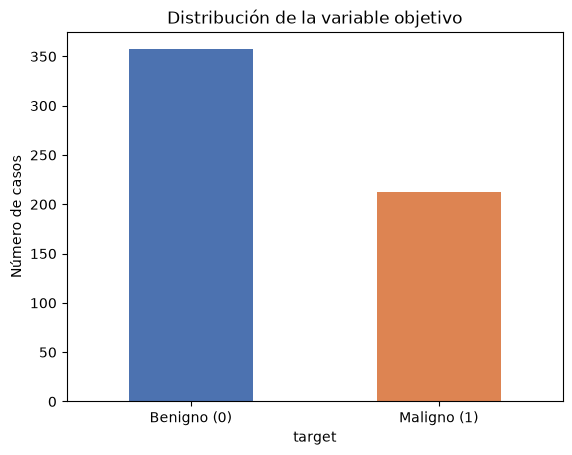

In [5]:
# Gráfico de la distribución de la variable objetivo
ax = y.map({0: 'Benigno (0)', 1: 'Maligno (1)'}).value_counts().plot(kind='bar', color=['#4C72B0', '#DD8452'])
ax.set_title('Distribución de la variable objetivo'); ax.set_ylabel('Número de casos')
plt.xticks(rotation=0); plt.show()

** ¿Cuántas observaciones y variables contiene el conjunto de datos?**
Contiene **569 observaciones** y **30 variables de entrada**, todas numéricas continuas (radio, textura, perímetro, área, suavidad, concavidad, etc., en sus versiones *mean*, *error* y *worst*). No hay valores nulos, por lo que no se requiere imputación.

** ¿La variable objetivo está balanceada?**
No completamente: hay **357 benignos (62,7 %)** y **212 malignos (37,3 %)**. Es un desbalance moderado (aprox. 1,7 : 1). No es extremo, pero implica que un modelo que prediga siempre "benigno" ya tendría ~63 % de Accuracy; por eso la Accuracy sola no basta y hay que mirar Recall y Precision de la clase maligna.

** ¿Por qué es importante definir con claridad qué representa la clase positiva?**
Porque Precision, Recall y F1 se calculan **sobre la clase positiva**. Si la clase 1 fuera "benigno", un Recall alto significaría detectar bien los benignos, que no es lo que interesa. Al definir 1 = maligno, los **falsos negativos** son malignos clasificados como benignos (el error más grave) y el Recall mide directamente cuántos malignos detecta el modelo.

### 1.2 División entrenamiento / prueba (común para todos los modelos)

In [6]:
# 80 % entrenamiento, 20 % prueba. random_state fija la semilla para reproducibilidad
# stratify=y conserva la proporción benigno/maligno en ambos subconjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('Entrenamiento:', X_train.shape, ' Prueba:', X_test.shape)
print('Proporción de malignos -> train: %.3f | test: %.3f' % (y_train.mean(), y_test.mean()))
print('Casos en prueba:', y_test.value_counts().to_dict())

Entrenamiento: (455, 30)  Prueba: (114, 30)
Proporción de malignos -> train: 0.374 | test: 0.368
Casos en prueba: {0: 72, 1: 42}


** ¿Qué función cumple `stratify=y`?**
Garantiza que la proporción de clases (≈ 37 % malignos) sea la misma en entrenamiento y en prueba. Así el conjunto de prueba (114 casos: 72 benignos y 42 malignos) es representativo y la comparación entre modelos no se ve afectada por una partición "con suerte" que deje pocos malignos en prueba. Este mismo `X_test` **no se modifica** en el resto del notebook.

### 1.3 Función común de evaluación

In [7]:
# Lista donde se acumulan los resultados de todos los modelos
resultados = []
# Diccionario para guardar las matrices de confusión y graficarlas al final
matrices = {}

def evaluar_modelo(nombre, modelo, X_eval, y_eval):
    """Predice sobre X_eval, imprime las métricas y la matriz de confusión,
    y devuelve un diccionario con los resultados."""
    pred = modelo.predict(X_eval)
    cm = confusion_matrix(y_eval, pred)
    tn, fp, fn, tp = cm.ravel()
    res = {
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_eval, pred),
        'Precision': precision_score(y_eval, pred),
        'Recall': recall_score(y_eval, pred),
        'F1': f1_score(y_eval, pred),
        'FN': fn,   # malignos clasificados como benignos (error crítico)
        'FP': fp    # benignos clasificados como malignos (falsa alarma)
    }
    print(f'===== {nombre} =====')
    for k in ['Accuracy', 'Precision', 'Recall', 'F1']:
        print(f'{k:<10}: {res[k]:.4f}')
    print('Matriz de confusión (filas = real, columnas = predicho; 0 = benigno, 1 = maligno):')
    print(cm)
    print(f'VN={tn}  FP={fp}  FN={fn}  VP={tp}\n')
    matrices[nombre] = cm
    return res

## 2. Ejercicio 2 — Decision Tree (Árbol de Decisión)
Se limita la profundidad a 4 niveles para obtener un modelo interpretable y reducir el sobreajuste. Los árboles **no necesitan escalamiento** porque dividen por umbrales en cada variable.

In [8]:
# Árbol de decisión con profundidad máxima 4
modelo_dt = DecisionTreeClassifier(max_depth=4, random_state=42)

# Entrenamiento con los datos de entrenamiento (sin escalar)
modelo_dt.fit(X_train, y_train)

# Evaluación sobre el conjunto de prueba común
resultados.append(evaluar_modelo('Decision Tree', modelo_dt, X_test, y_test))

===== Decision Tree =====
Accuracy  : 0.9123
Precision : 0.9444
Recall    : 0.8095
F1        : 0.8718
Matriz de confusión (filas = real, columnas = predicho; 0 = benigno, 1 = maligno):
[[70  2]
 [ 8 34]]
VN=70  FP=2  FN=8  VP=34



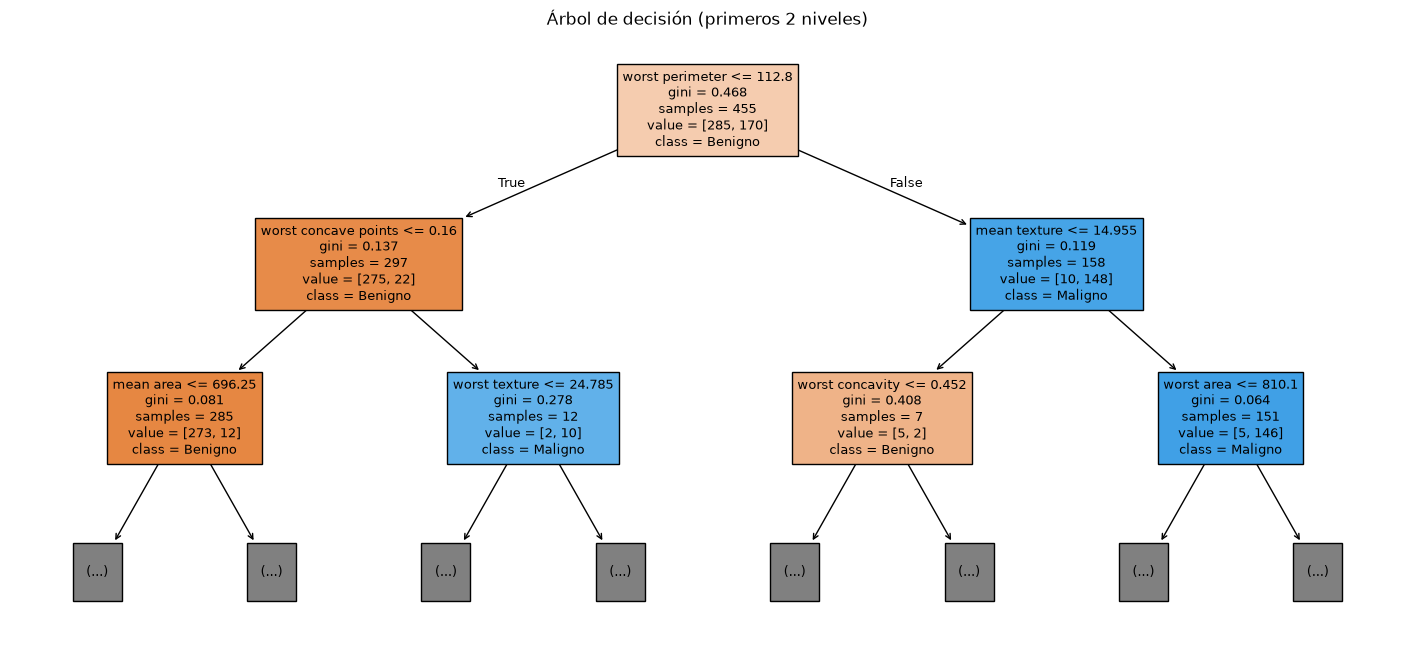

worst perimeter         0.784310
worst concave points    0.072538
mean texture            0.031234
worst smoothness        0.026578
mean area               0.024057
dtype: float64

In [9]:
# Visualización del árbol (primeros niveles) para mostrar su interpretabilidad
plt.figure(figsize=(18, 8))
plot_tree(modelo_dt, feature_names=X.columns, class_names=['Benigno', 'Maligno'],
          filled=True, max_depth=2, fontsize=9)
plt.title('Árbol de decisión (primeros 2 niveles)'); plt.show()

# Variables más importantes según el árbol
pd.Series(modelo_dt.feature_importances_, index=X.columns).sort_values(ascending=False).head(5)

** ¿Qué ventaja tiene limitar la profundidad del árbol?**
Un árbol sin límite crece hasta memorizar el entrenamiento (sobreajuste). Con `max_depth=4` el modelo es más **simple, generaliza mejor y se puede leer como reglas "si… entonces…"**. Aquí se ve que el árbol depende casi por completo de `worst perimeter` (≈ 78 % de la importancia) y `worst concave points`.

** ¿Qué errores observas en la matriz de confusión?**
Matriz `[[70, 2], [8, 34]]`: acierta 70 benignos y 34 malignos, pero tiene **8 falsos negativos** (malignos que clasifica como benignos) y 2 falsos positivos. El Recall es de solo **0,81**: deja sin detectar casi 1 de cada 5 malignos. Es el peor desempeño en la clase de interés, porque un solo árbol con pocas divisiones no captura bien los casos frontera.

## 3. Ejercicio 3 — Random Forest
Conjunto de 100 árboles entrenados con muestras bootstrap y subconjuntos aleatorios de variables; la predicción final es por votación mayoritaria. Tampoco requiere escalamiento.

In [10]:
# Random Forest con 100 árboles
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Entrenamiento
modelo_rf.fit(X_train, y_train)

# Evaluación
resultados.append(evaluar_modelo('Random Forest', modelo_rf, X_test, y_test))

===== Random Forest =====
Accuracy  : 0.9737
Precision : 1.0000
Recall    : 0.9286
F1        : 0.9630
Matriz de confusión (filas = real, columnas = predicho; 0 = benigno, 1 = maligno):
[[72  0]
 [ 3 39]]
VN=72  FP=0  FN=3  VP=39



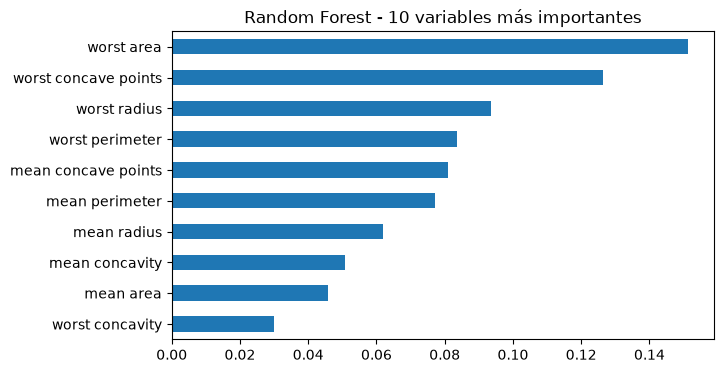

In [11]:
# Importancia de variables: a diferencia del árbol, se reparte entre varias
imp_rf = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp_rf.sort_values().plot(kind='barh', figsize=(7, 4), title='Random Forest - 10 variables más importantes')
plt.show()

** ¿Qué cambia al pasar de un árbol individual a un conjunto de árboles?**
Cada árbol ve datos y variables ligeramente distintos, y al votar entre 100 árboles se **reduce la varianza**: los errores individuales se compensan. La importancia ya no se concentra en una sola variable, sino que se reparte (`worst area`, `worst concave points`, `worst radius`, `worst perimeter`, `mean concave points`), lo que hace el modelo más robusto. El costo es que se pierde la lectura directa de reglas.

** ¿Mejora alguna métrica? ¿Cuál y cuánto?**
Mejoran todas frente al Decision Tree:

| Métrica | Decision Tree | Random Forest | Diferencia |
|---|---|---|---|
| Accuracy | 0,9123 | 0,9737 | +6,1 pp |
| Precision | 0,9444 | 1,0000 | +5,6 pp |
| Recall | 0,8095 | 0,9286 | **+11,9 pp** |
| F1 | 0,8718 | 0,9630 | +9,1 pp |

La mejora más importante es el **Recall**: los falsos negativos bajan de 8 a 3, y los falsos positivos de 2 a 0.

## 4. Ejercicio 4 — Support Vector Machine (SVM)
SVM busca el hiperplano de máximo margen; con kernel RBF puede separar clases de forma no lineal. Es sensible a la escala, por lo que el `StandardScaler` va dentro de un `Pipeline` (el escalador se ajusta **solo** con los datos de entrenamiento, evitando fuga de información hacia el conjunto de prueba).

In [12]:
# Pipeline: estandarización (media 0, desviación 1) + SVM con kernel RBF
modelo_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1.0, gamma='scale')
)

# Entrenamiento: el pipeline ajusta el escalador y luego el SVM con X_train
modelo_svm.fit(X_train, y_train)

# Evaluación: el pipeline aplica la misma transformación a X_test antes de predecir
resultados.append(evaluar_modelo('SVM', modelo_svm, X_test, y_test))

===== SVM =====
Accuracy  : 0.9737
Precision : 1.0000
Recall    : 0.9286
F1        : 0.9630
Matriz de confusión (filas = real, columnas = predicho; 0 = benigno, 1 = maligno):
[[72  0]
 [ 3 39]]
VN=72  FP=0  FN=3  VP=39



** ¿Por qué usamos `StandardScaler`?**
Las variables tienen escalas muy distintas: `worst area` llega a ~4.254, mientras `fractal dimension error` no pasa de ~0,03. El kernel RBF calcula distancias entre puntos; sin escalar, las variables grandes dominarían por completo y las pequeñas serían ignoradas. Estandarizar pone todas en la misma escala para que cada una aporte según su información, no según su unidad de medida.

** ¿Qué resultado obtiene SVM frente a los modelos basados en árboles?**
SVM obtiene **Accuracy 0,9737, Precision 1,00, Recall 0,9286 y F1 0,9630**, con matriz `[[72, 0], [3, 39]]`: idéntica a Random Forest en el conjunto de prueba y claramente superior al Decision Tree (5 falsos negativos menos). Es decir, con una sola frontera de decisión bien escalada alcanza el mismo desempeño que un conjunto de 100 árboles.

## 5. Ejercicio 5 — K-Nearest Neighbors (K-NN)
K-NN clasifica cada caso según la clase mayoritaria de sus *k* vecinos más cercanos (distancia euclidiana). El escalamiento se mantiene dentro del Pipeline.

In [13]:
# Pipeline: estandarización + K-NN con k = 5 vecinos
modelo_knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Entrenamiento (K-NN básicamente "memoriza" los datos de entrenamiento escalados)
modelo_knn.fit(X_train, y_train)

# Evaluación
resultados.append(evaluar_modelo('K-NN', modelo_knn, X_test, y_test))

===== K-NN =====
Accuracy  : 0.9561
Precision : 0.9744
Recall    : 0.9048
F1        : 0.9383
Matriz de confusión (filas = real, columnas = predicho; 0 = benigno, 1 = maligno):
[[71  1]
 [ 4 38]]
VN=71  FP=1  FN=4  VP=38



** ¿Qué representa k=5?**
Que para clasificar una muestra nueva se buscan las **5 muestras de entrenamiento más cercanas** y se asigna la clase que tenga mayoría entre ellas (al menos 3 de 5). Un k pequeño hace al modelo sensible al ruido; uno grande suaviza demasiado la frontera. k=5 es un punto intermedio habitual, e impar para evitar empates.

** ¿Por qué el escalamiento es especialmente importante cuando se calculan distancias?**
Porque la distancia euclidiana suma diferencias al cuadrado de todas las variables: una diferencia de 500 en `worst area` aplastaría una diferencia de 0,01 en `smoothness`, aunque esta última sea muy informativa. Sin escalar, "vecino cercano" significaría prácticamente "de área parecida". Resultado obtenido: Accuracy 0,9561, Recall 0,9048, con 4 falsos negativos y 1 falso positivo.

## 6. Ejercicio 6 — Naive Bayes (GaussianNB)
Modelo probabilístico basado en el teorema de Bayes. `GaussianNB` asume que cada variable sigue una distribución normal dentro de cada clase. Se usa sin escalamiento, como indica la guía.

In [14]:
# Naive Bayes Gaussiano (sin escalamiento: estima media y varianza por variable y clase)
modelo_nb = GaussianNB()

# Entrenamiento
modelo_nb.fit(X_train, y_train)

# Evaluación
resultados.append(evaluar_modelo('Naive Bayes', modelo_nb, X_test, y_test))

===== Naive Bayes =====
Accuracy  : 0.9386
Precision : 1.0000
Recall    : 0.8333
F1        : 0.9091
Matriz de confusión (filas = real, columnas = predicho; 0 = benigno, 1 = maligno):
[[72  0]
 [ 7 35]]
VN=72  FP=0  FN=7  VP=35



** ¿Qué supuesto simplificador utiliza Naive Bayes?**
Supone que las variables son **condicionalmente independientes entre sí dada la clase** (de ahí lo de "ingenuo"). En este dataset ese supuesto se incumple claramente: radio, perímetro y área están casi perfectamente correlacionados, así que el modelo "cuenta varias veces" la misma evidencia. Aun así funciona razonablemente, porque solo necesita ordenar bien las probabilidades, no estimarlas con exactitud.

** ¿En qué métricas se comporta mejor o peor?**
- **Mejor:** Precision = **1,00** (cero falsos positivos, igual que RF y SVM): cuando dice "maligno", acierta siempre.
- **Peor:** Recall = **0,8333**, con **7 falsos negativos**; solo el Decision Tree lo hace peor. Su Accuracy (0,9386) y F1 (0,9091) quedan por debajo de RF, SVM y K-NN. Es un modelo "conservador": prefiere decir benigno ante la duda, lo cual es justo el error más costoso aquí.

### (Opcional) Línea base — Regresión Logística
Se incluye como referencia, con el mismo escalamiento y la misma partición.

In [15]:
# Regresión logística con escalamiento (max_iter alto para asegurar convergencia)
modelo_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modelo_lr.fit(X_train, y_train)
res_lr = evaluar_modelo('Reg. Logística (base)', modelo_lr, X_test, y_test)

===== Reg. Logística (base) =====
Accuracy  : 0.9649
Precision : 0.9750
Recall    : 0.9286
F1        : 0.9512
Matriz de confusión (filas = real, columnas = predicho; 0 = benigno, 1 = maligno):
[[71  1]
 [ 3 39]]
VN=71  FP=1  FN=3  VP=39



## 7. Ejercicio 7 — Comparación y toma de decisión
### 7.1 Tabla comparativa

In [16]:
# Consolidar los resultados de los cinco modelos en un DataFrame
tabla = pd.DataFrame(resultados).set_index('Modelo')

# Observación breve de cada modelo (interpretación, no solo números)
tabla['Observación'] = [
    'Interpretable, pero 8 FN: el peor Recall',
    'Sin FP, 3 FN; muy sólido y sin escalar',
    'Sin FP, 3 FN; empata con RF en prueba',
    'Buen balance; 4 FN y 1 FP',
    'Precision perfecta, pero 7 FN'
]
tabla.round(4)

,Accuracy,Precision,Recall,F1,FN,FP,Observación
Modelo,,,,,,,
Decision Tree,0.9123,0.9444,0.8095,0.8718,8,2,"Interpretable, pero 8 FN: el peor Recall"
Random Forest,0.9737,1.0000,0.9286,0.9630,3,0,"Sin FP, 3 FN; muy sólido y sin escalar"
SVM,0.9737,1.0000,0.9286,0.9630,3,0,"Sin FP, 3 FN; empata con RF en prueba"
K-NN,0.9561,0.9744,0.9048,0.9383,4,1,Buen balance; 4 FN y 1 FP
Naive Bayes,0.9386,1.0000,0.8333,0.9091,7,0,"Precision perfecta, pero 7 FN"


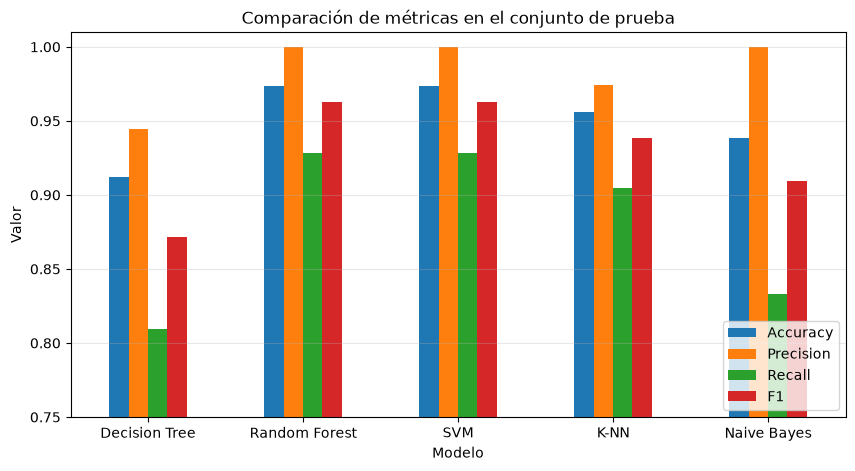

In [17]:
# Comparación visual de las cuatro métricas
tabla[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(10, 5), ylim=(0.75, 1.01))
plt.title('Comparación de métricas en el conjunto de prueba'); plt.ylabel('Valor')
plt.xticks(rotation=0); plt.legend(loc='lower right'); plt.grid(axis='y', alpha=.3); plt.show()

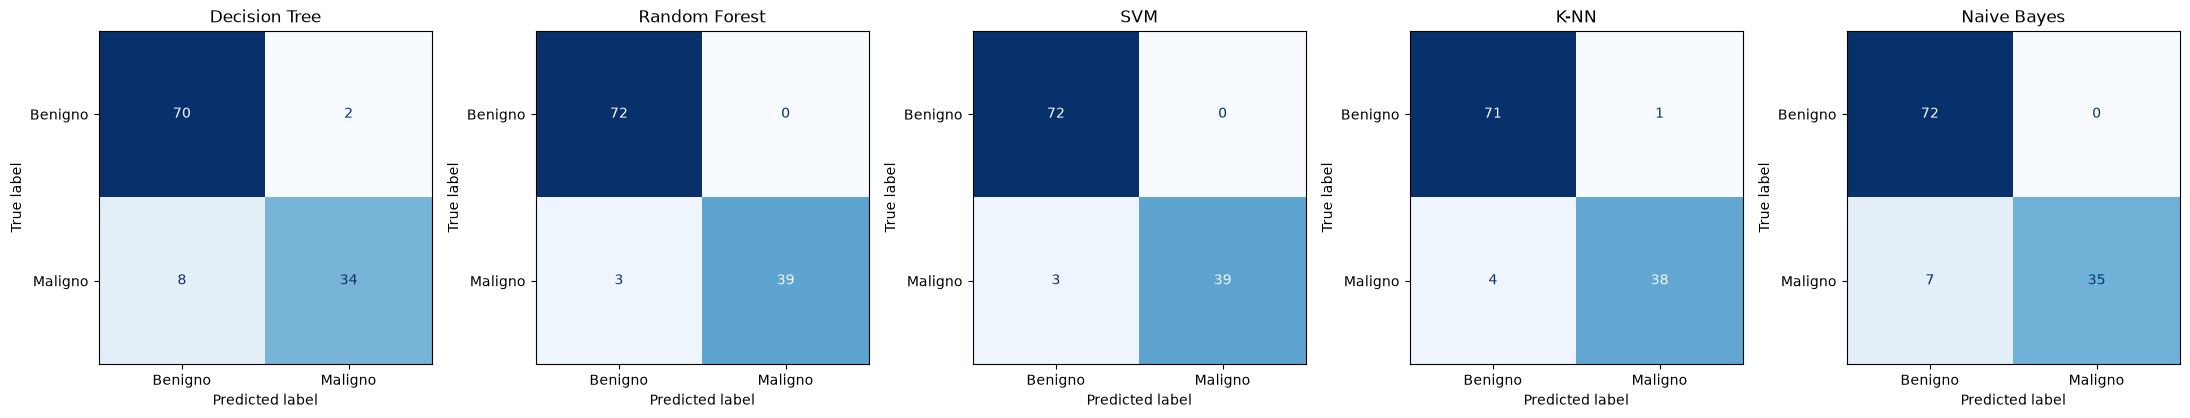

In [18]:
# Matrices de confusión de los cinco modelos, lado a lado
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (nombre, cm) in zip(axes, list(matrices.items())[:5]):
    ConfusionMatrixDisplay(cm, display_labels=['Benigno', 'Maligno']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(nombre)
plt.tight_layout(); plt.show()

### 7.2 Interpretación de las matrices de confusión
Las matrices se leen como `[[VN, FP], [FN, VP]]`. En prueba hay 72 benignos y 42 malignos.

| Modelo | VN | FP | FN | VP | Lectura |
|---|---|---|---|---|---|
| Decision Tree | 70 | 2 | **8** | 34 | Pierde 19 % de los malignos |
| Random Forest | 72 | 0 | **3** | 39 | Ninguna falsa alarma; 3 malignos no detectados |
| SVM | 72 | 0 | **3** | 39 | Mismo patrón que Random Forest |
| K-NN | 71 | 1 | **4** | 38 | Muy cercano a los mejores |
| Naive Bayes | 72 | 0 | **7** | 35 | Conservador: casi no da falsos positivos, pero sí muchos FN |

Patrón común: **los errores son casi todos falsos negativos**. Todos los modelos clasifican muy bien los benignos (70–72 de 72), y la diferencia entre ellos está en cuántos malignos se les escapan.

### 7.3 Verificación adicional: validación cruzada en el entrenamiento
Random Forest y SVM empatan exactamente en el conjunto de prueba (114 casos). Para desempatar **sin tocar el conjunto de prueba**, se aplica validación cruzada estratificada de 5 particiones solo sobre `X_train`. La desviación estándar indica qué tan estable es cada modelo.

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelos = {'Decision Tree': modelo_dt, 'Random Forest': modelo_rf, 'SVM': modelo_svm,
           'K-NN': modelo_knn, 'Naive Bayes': modelo_nb}
filas = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=['accuracy', 'recall', 'f1'])
    filas.append({'Modelo': nombre,
                  'Accuracy CV': r['test_accuracy'].mean(), 'Recall CV': r['test_recall'].mean(),
                  'Recall CV (desv.)': r['test_recall'].std(), 'F1 CV': r['test_f1'].mean(),
                  'F1 CV (desv.)': r['test_f1'].std()})
pd.DataFrame(filas).set_index('Modelo').round(4)

,Accuracy CV,Recall CV,Recall CV (desv.),F1 CV,F1 CV (desv.)
Modelo,,,,,
Decision Tree,0.9209,0.8647,0.0780,0.8897,0.0537
Random Forest,0.9648,0.9412,0.0416,0.9519,0.0207
SVM,0.9714,0.9471,0.0343,0.9610,0.0082
K-NN,0.9648,0.9176,0.0343,0.9510,0.0263
Naive Bayes,0.9407,0.9000,0.0546,0.9185,0.0361


En validación cruzada **SVM queda primero** entre los cinco: Accuracy 0,971, Recall 0,947 y F1 0,961, con la menor variabilidad en F1 (desv. ≈ 0,008 frente a ≈ 0,021 de Random Forest). Confirma que su resultado en prueba no fue casualidad.

### 7.4 Diferencias entre algoritmos con y sin escalamiento
Para evidenciar el efecto, se entrena SVM y K-NN **sin** `StandardScaler` (solo como experimento; no reemplaza los modelos anteriores).

In [20]:
# Experimento: los mismos algoritmos sin escalar
for nombre, m in [('SVM sin escalar', SVC(kernel='rbf', C=1.0, gamma='scale')),
                  ('K-NN sin escalar', KNeighborsClassifier(n_neighbors=5))]:
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    print(f'{nombre:<17} Accuracy={accuracy_score(y_test, p):.4f}  Recall={recall_score(y_test, p):.4f}  FN={confusion_matrix(y_test, p)[1,0]}')

SVM sin escalar   Accuracy=0.9035  Recall=0.7381  FN=11
K-NN sin escalar  Accuracy=0.9123  Recall=0.7857  FN=9


Sin escalar, SVM cae a Recall ≈ 0,74 (11 FN) y K-NN a ≈ 0,79 (9 FN): pierden entre 14 y 19 puntos de Recall. Con escalamiento, ambos quedan entre los mejores. Los modelos de árboles y Naive Bayes no cambian con el escalamiento, porque usan umbrales por variable o distribuciones por variable, no distancias.

### 7.5 Preguntas de análisis

**7. ¿Qué modelo obtuvo la mayor Accuracy?**
**Random Forest y SVM empatan** con 0,9737 (111 de 114 aciertos). Siguen K-NN (0,9561), Naive Bayes (0,9386) y Decision Tree (0,9123).

**8. ¿Qué modelo obtuvo el mayor Recall para la clase maligna?**
De nuevo **Random Forest y SVM** con 0,9286 (39 de 42 malignos detectados). K-NN alcanza 0,9048, Naive Bayes 0,8333 y Decision Tree 0,8095.

**9. ¿Qué modelo produjo menos falsos negativos?**
**Random Forest y SVM, con 3 falsos negativos** cada uno. K-NN tiene 4, Naive Bayes 7 y Decision Tree 8.

**10. ¿Coincide el modelo con mayor Accuracy con el que seleccionarías?**
Sí, pero **no por la Accuracy**. La Accuracy de 0,97 coincide aquí con el mejor Recall y el menor número de falsos negativos, que es lo que realmente importa. Si el modelo con mayor Accuracy hubiera tenido más falsos negativos, no lo elegiría: un modelo que siempre dice "benigno" ya obtiene 63 % de Accuracy sin detectar ningún maligno. Además, entre los dos empatados la Accuracy no decide nada; el desempate se hace con validación cruzada y criterios de contexto.

**11. Si el costo de no detectar un caso maligno fuera especialmente alto, ¿qué métrica priorizarías?**
El **Recall de la clase maligna** (sensibilidad), porque mide directamente qué proporción de malignos se detectan: Recall = VP / (VP + FN). Un falso negativo significa que una persona con un caso maligno se iría sin seguimiento, mientras que un falso positivo genera una prueba adicional. Por eso conviene aceptar algo menos de Precision a cambio de menos falsos negativos (por ejemplo, bajando el umbral de decisión), y vigilar el F1 para que la Precision no se desplome.

**12. ¿Cuál de los modelos es más sencillo de explicar a una persona no técnica?**
El **Decision Tree**: se puede dibujar y leer como reglas del tipo *"si el perímetro máximo es mayor a X y los puntos cóncavos superan Y, entonces maligno"*. Naive Bayes también es explicable en términos de probabilidades. SVM con kernel RBF, Random Forest (100 árboles) y K-NN en 30 dimensiones son mucho más difíciles de explicar.

**13. ¿Qué diferencias observaste entre los algoritmos que requieren escalamiento y los que no?**
SVM y K-NN dependen de distancias, por lo que **sin escalar empeoran mucho** (Recall de 0,74 y 0,79) y **con escalamiento quedan entre los mejores** (0,93 y 0,90). Decision Tree, Random Forest y Naive Bayes trabajan variable por variable, así que son indiferentes a la escala y se pueden usar con los datos crudos, lo que simplifica su preparación. La lección práctica: el escalamiento no es opcional para modelos basados en distancias, y debe hacerse dentro de un Pipeline para no filtrar información del conjunto de prueba.

**14. Selección del modelo final y justificación**
Selecciono **SVM (kernel RBF, con StandardScaler en un Pipeline)**:
1. **Recall = 0,9286 y 3 falsos negativos**, el mejor resultado en la métrica prioritaria, empatado con Random Forest.
2. **Precision = 1,00 y F1 = 0,9630**: ninguna falsa alarma y el mejor equilibrio entre ambos tipos de error.
3. **Desempate con validación cruzada:** SVM supera a Random Forest en Recall CV (0,947 vs 0,941) y en F1 CV (0,961 vs 0,952), con menor variabilidad, por lo que se espera un comportamiento más estable con datos nuevos.
4. **Contexto:** en un problema diagnóstico el error crítico es el falso negativo; SVM es el que mejor y más establemente lo minimiza. Su debilidad es la interpretabilidad, que se puede compensar acompañándolo de un árbol como apoyo explicativo o de análisis de importancia de variables.

**Alternativa válida:** Random Forest, si se prioriza no tener que escalar los datos y contar con importancia de variables incorporada; su desempeño en prueba es idéntico.

> **Idea clave:** el mejor modelo no es el de mayor número en una sola métrica, sino el que combina menos errores del tipo costoso (falsos negativos), estabilidad, y una interpretabilidad suficiente para el propósito del problema.

## 8. Conclusiones
1. Con la misma partición y las mismas métricas, las diferencias se deben al algoritmo: **SVM y Random Forest** lideran (Accuracy 0,974; Recall 0,929; 3 FN), seguidos de K-NN, Naive Bayes y Decision Tree.
2. En todos los modelos **los errores son mayoritariamente falsos negativos**, el tipo de error más costoso en este contexto; por eso el Recall pesa más que la Accuracy en la decisión.
3. El **escalamiento** es determinante para SVM y K-NN (+14 a +19 pp de Recall) e irrelevante para árboles y Naive Bayes.
4. Existe un compromiso **desempeño vs. interpretabilidad**: el árbol es el más fácil de explicar, pero el que más malignos deja sin detectar.
5. El modelo final recomendado es **SVM con escalamiento**, por su Recall, Precision perfecta en prueba y mayor estabilidad en validación cruzada.

## Referencias
- Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Scikit-learn. `sklearn.datasets.load_breast_cancer`. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
- Universidad de Cundinamarca. Guía Semana 8 — Implementación y comparación de algoritmos de clasificación. CADI Introducción a Machine Learning.